In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
data = pd.read_excel(
    "CFD_Methane_ML_Ready_64_Cases.xlsx",
    sheet_name="ML_Dataset"
)

print("Dataset loaded successfully")
print("Number of rows and columns:", data.shape)

Dataset loaded successfully
Number of rows and columns: (64, 10)


In [3]:
data.head()

,Case_ID,Leak_Diameter_mm,Leak_Rate_kg_s_REFERENCE,Wind_Speed_m_s,Wind_Direction,Wind_Direction_deg,Wind_Sin,Wind_Cos,Max_3D_LFL_Distance_m,Flammable_Hazard_Volume_m3
0,1,5,0.163,1,North,0,0.0,1.0,0.499663,0.001625
1,2,10,0.654,1,North,0,0.0,1.0,1.398640,0.017223
2,3,15,1.472,1,North,0,0.0,1.0,2.824440,0.077510
3,4,20,2.615,1,North,0,0.0,1.0,4.304310,0.229738
4,5,5,0.163,2,North,0,0.0,1.0,0.499538,0.001631


In [4]:
blind_case_ids = [1, 12, 18, 31, 35, 46, 56, 57]

development_data = data[
    ~data['Case_ID'].isin(blind_case_ids)
].copy()

blind_test_data = data[
    data['Case_ID'].isin(blind_case_ids)
].copy()

print("Total CFD cases:", len(data))
print("Development cases:", len(development_data))
print("Blind test cases:", len(blind_test_data))

Total CFD cases: 64
Development cases: 56
Blind test cases: 8


In [5]:
blind_test_data[[
    'Case_ID',
    'Leak_Diameter_mm',
    'Wind_Speed_m_s',
    'Wind_Direction'
]]

,Case_ID,Leak_Diameter_mm,Wind_Speed_m_s,Wind_Direction
0,1,5,1,North
11,12,20,4,North
17,18,10,1,East
30,31,15,6,East
34,35,15,1,South
45,46,10,6,South
55,56,20,2,West
56,57,5,4,West


In [6]:
features = [
    'Leak_Diameter_mm',
    'Wind_Speed_m_s',
    'Wind_Sin',
    'Wind_Cos'
]

X = development_data[features]

print("Input data shape:", X.shape)
X.head()

Input data shape: (56, 4)


,Leak_Diameter_mm,Wind_Speed_m_s,Wind_Sin,Wind_Cos
1,10,1,0.0,1.0
2,15,1,0.0,1.0
3,20,1,0.0,1.0
4,5,2,0.0,1.0
5,10,2,0.0,1.0


In [7]:
y_distance = development_data[
    'Max_3D_LFL_Distance_m'
]

print("Target data shape:", y_distance.shape)
y_distance.head()

Target data shape: (56,)


1    1.398640
2    2.824440
3    4.304310
4    0.499538
5    1.416260
Name: Max_3D_LFL_Distance_m, dtype: float64

In [8]:
print("Missing values in inputs:")
print(X.isnull().sum())

print("\nMissing values in target:")
print(y_distance.isnull().sum())

Missing values in inputs:
Leak_Diameter_mm    0
Wind_Speed_m_s      0
Wind_Sin            0
Wind_Cos            0
dtype: int64

Missing values in target:
0


In [9]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.ensemble import RandomForestRegressor
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-fold cross-validation ready")

5-fold cross-validation ready


In [10]:
rf_model = RandomForestRegressor(
    n_estimators=500,
    random_state=42
)

print("Random Forest created")

Random Forest created


In [11]:
scoring = {
    'MAE': 'neg_mean_absolute_error',
    'RMSE': 'neg_root_mean_squared_error',
    'R2': 'r2'
}

cv_results = cross_validate(
    rf_model,
    X,
    y_distance,
    cv=cv,
    scoring=scoring
)

print("Cross-validation completed")

Cross-validation completed


In [12]:
cv_mae = -cv_results['test_MAE']
cv_rmse = -cv_results['test_RMSE']
cv_r2 = cv_results['test_R2']

print("MODEL 1: MAX 3D LFL DISTANCE")
print("5-FOLD CROSS-VALIDATION RESULTS")
print("--------------------------------")

print(f"Mean MAE  = {cv_mae.mean():.4f} m")
print(f"Mean RMSE = {cv_rmse.mean():.4f} m")
print(f"Mean R²   = {cv_r2.mean():.4f}")

print("\nIndividual fold R² values:")
for i, score in enumerate(cv_r2, start=1):
    print(f"Fold {i}: {score:.4f}")

MODEL 1: MAX 3D LFL DISTANCE
5-FOLD CROSS-VALIDATION RESULTS
--------------------------------
Mean MAE  = 0.0250 m
Mean RMSE = 0.0400 m
Mean R²   = 0.9991

Individual fold R² values:
Fold 1: 0.9992
Fold 2: 0.9992
Fold 3: 0.9994
Fold 4: 0.9998
Fold 5: 0.9981


In [13]:
development_data.groupby('Leak_Diameter_mm')[
    'Max_3D_LFL_Distance_m'
].agg(['mean', 'min', 'max', 'std'])

,mean,min,max,std
Leak_Diameter_mm,,,,
5,0.520182,0.499036,0.525935,0.009003
10,1.346466,1.237020,1.422200,0.078350
15,2.810976,2.769510,2.843790,0.027641
20,4.261882,3.974240,4.431640,0.132909


In [14]:
correlation = development_data[
    ['Leak_Diameter_mm',
     'Wind_Speed_m_s',
     'Max_3D_LFL_Distance_m']
].corr()

correlation

,Leak_Diameter_mm,Wind_Speed_m_s,Max_3D_LFL_Distance_m
Leak_Diameter_mm,1.000000,-0.012584,0.991316
Wind_Speed_m_s,-0.012584,1.000000,-0.010136
Max_3D_LFL_Distance_m,0.991316,-0.010136,1.000000


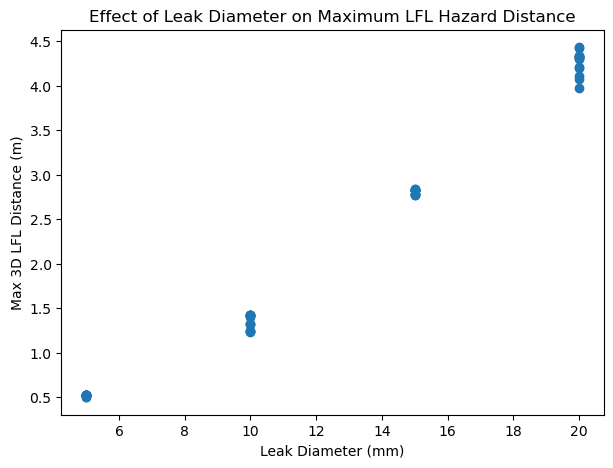

In [15]:
plt.figure(figsize=(7,5))

plt.scatter(
    development_data['Leak_Diameter_mm'],
    development_data['Max_3D_LFL_Distance_m']
)

plt.xlabel('Leak Diameter (mm)')
plt.ylabel('Max 3D LFL Distance (m)')
plt.title('Effect of Leak Diameter on Maximum LFL Hazard Distance')

plt.show()

In [16]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_cv_results = cross_validate(
    linear_model,
    X,
    y_distance,
    cv=cv,
    scoring=scoring
)

linear_mae = -linear_cv_results['test_MAE']
linear_rmse = -linear_cv_results['test_RMSE']
linear_r2 = linear_cv_results['test_R2']

print("LINEAR REGRESSION - 5-FOLD CROSS-VALIDATION")
print("-------------------------------------------")
print(f"Mean MAE  = {linear_mae.mean():.4f} m")
print(f"Mean RMSE = {linear_rmse.mean():.4f} m")
print(f"Mean R²   = {linear_r2.mean():.4f}")

LINEAR REGRESSION - 5-FOLD CROSS-VALIDATION
-------------------------------------------
Mean MAE  = 0.1675 m
Mean RMSE = 0.1950 m
Mean R²   = 0.9794


In [17]:
final_rf_distance = RandomForestRegressor(
    n_estimators=500,
    random_state=42
)

final_rf_distance.fit(X, y_distance)

print("Final Model 1 trained on 56 development cases")

Final Model 1 trained on 56 development cases


In [18]:
X_blind = blind_test_data[features]

X_blind

,Leak_Diameter_mm,Wind_Speed_m_s,Wind_Sin,Wind_Cos
0,5,1,0.000000e+00,1.000000e+00
11,20,4,0.000000e+00,1.000000e+00
17,10,1,1.000000e+00,6.125742e-17
30,15,6,1.000000e+00,6.125742e-17
34,15,1,1.225148e-16,-1.000000e+00
45,10,6,1.225148e-16,-1.000000e+00
55,20,2,-1.000000e+00,-1.837723e-16
56,5,4,-1.000000e+00,-1.837723e-16


In [19]:
blind_predictions_distance = final_rf_distance.predict(X_blind)

blind_prediction_table = pd.DataFrame({
    'Case_ID': blind_test_data['Case_ID'].values,
    'Predicted_Max_3D_LFL_Distance_m': blind_predictions_distance
})

blind_prediction_table

,Case_ID,Predicted_Max_3D_LFL_Distance_m
0,1,0.502669
1,12,4.274098
2,18,1.402668
3,31,2.800095
4,35,2.838075
5,46,1.323594
6,56,4.097352
7,57,0.524213


In [20]:
blind_results_distance = pd.DataFrame({
    'Case_ID': blind_test_data['Case_ID'].values,
    'Actual_CFD_m': blind_test_data[
        'Max_3D_LFL_Distance_m'
    ].values,
    'Predicted_ML_m': blind_predictions_distance
})

blind_results_distance['Error_m'] = (
    blind_results_distance['Predicted_ML_m']
    - blind_results_distance['Actual_CFD_m']
)

blind_results_distance['Absolute_Error_m'] = (
    blind_results_distance['Error_m'].abs()
)

blind_results_distance

,Case_ID,Actual_CFD_m,Predicted_ML_m,Error_m,Absolute_Error_m
0,1,0.499663,0.502669,0.003006,0.003006
1,12,4.319820,4.274098,-0.045722,0.045722
2,18,1.420810,1.402668,-0.018142,0.018142
3,31,2.769830,2.800095,0.030265,0.030265
4,35,2.837530,2.838075,0.000545,0.000545
5,46,1.324420,1.323594,-0.000826,0.000826
6,56,4.108940,4.097352,-0.011588,0.011588
7,57,0.524912,0.524213,-0.000699,0.000699


In [21]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

actual = blind_results_distance['Actual_CFD_m']
predicted = blind_results_distance['Predicted_ML_m']

blind_mae = mean_absolute_error(actual, predicted)
blind_rmse = np.sqrt(mean_squared_error(actual, predicted))
blind_r2 = r2_score(actual, predicted)

print("MODEL 1: FINAL BLIND TEST")
print("-------------------------")
print(f"MAE  = {blind_mae:.4f} m")
print(f"RMSE = {blind_rmse:.4f} m")
print(f"R²   = {blind_r2:.4f}")

MODEL 1: FINAL BLIND TEST
-------------------------
MAE  = 0.0138 m
RMSE = 0.0209 m
R²   = 0.9998


In [22]:
blind_results_distance['Percentage_Error'] = (
    blind_results_distance['Absolute_Error_m']
    / blind_results_distance['Actual_CFD_m']
) * 100

blind_results_distance

,Case_ID,Actual_CFD_m,Predicted_ML_m,Error_m,Absolute_Error_m,Percentage_Error
0,1,0.499663,0.502669,0.003006,0.003006,0.601603
1,12,4.319820,4.274098,-0.045722,0.045722,1.058427
2,18,1.420810,1.402668,-0.018142,0.018142,1.276896
3,31,2.769830,2.800095,0.030265,0.030265,1.092662
4,35,2.837530,2.838075,0.000545,0.000545,0.019216
5,46,1.324420,1.323594,-0.000826,0.000826,0.062349
6,56,4.108940,4.097352,-0.011588,0.011588,0.282017
7,57,0.524912,0.524213,-0.000699,0.000699,0.133192


In [23]:
print(
    "Mean Absolute Percentage Error =",
    round(blind_results_distance['Percentage_Error'].mean(), 2),
    "%"
)

print(
    "Maximum Percentage Error =",
    round(blind_results_distance['Percentage_Error'].max(), 2),
    "%"
)

Mean Absolute Percentage Error = 0.57 %
Maximum Percentage Error = 1.28 %


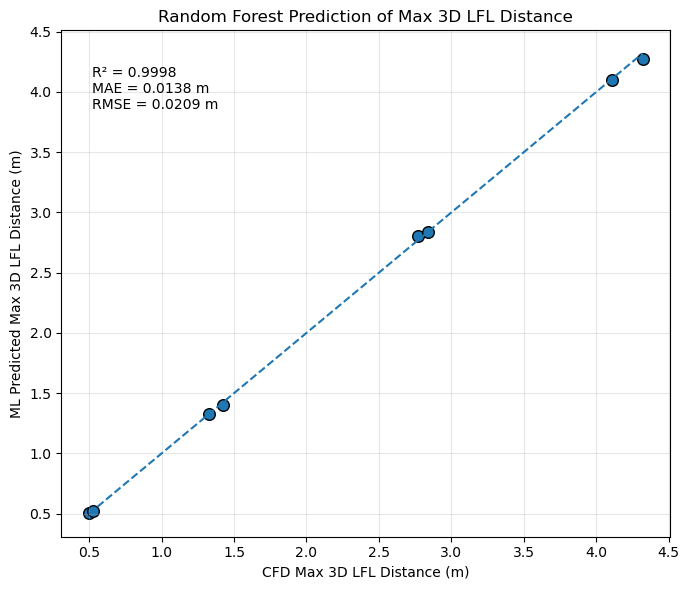

In [24]:
plt.figure(figsize=(7,6))

plt.scatter(
    actual,
    predicted,
    s=70,
    edgecolors='black'
)

minimum = min(actual.min(), predicted.min())
maximum = max(actual.max(), predicted.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    '--',
    linewidth=1.5
)

plt.xlabel('CFD Max 3D LFL Distance (m)')
plt.ylabel('ML Predicted Max 3D LFL Distance (m)')
plt.title('Random Forest Prediction of Max 3D LFL Distance')

plt.text(
    0.05,
    0.93,
    f'R² = {blind_r2:.4f}\nMAE = {blind_mae:.4f} m\nRMSE = {blind_rmse:.4f} m',
    transform=plt.gca().transAxes,
    verticalalignment='top'
)

plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [25]:
from sklearn.linear_model import LinearRegression

# Create a copy of the input data
X_equation = development_data[[
    'Leak_Diameter_mm',
    'Wind_Speed_m_s',
    'Wind_Sin',
    'Wind_Cos'
]].copy()

# Add diameter squared
X_equation['Diameter_Squared'] = (
    X_equation['Leak_Diameter_mm'] ** 2
)

# Put columns in equation order
X_equation = X_equation[[
    'Leak_Diameter_mm',
    'Diameter_Squared',
    'Wind_Speed_m_s',
    'Wind_Sin',
    'Wind_Cos'
]]

equation_model = LinearRegression()

equation_model.fit(
    X_equation,
    y_distance
)

print("Intercept =", equation_model.intercept_)

for name, coefficient in zip(
    X_equation.columns,
    equation_model.coef_
):
    print(name, "=", coefficient)

print("R² =", equation_model.score(X_equation, y_distance))

Intercept = -0.17794318411974963
Leak_Diameter_mm = 0.10201461218691123
Diameter_Squared = 0.006071067698885674
Wind_Speed_m_s = -0.00021057955427034034
Wind_Sin = 0.06721880894847007
Wind_Cos = 0.005758318892753794
R² = 0.9957154441567719


In [26]:
X_equation_blind = blind_test_data[[
    'Leak_Diameter_mm',
    'Wind_Speed_m_s',
    'Wind_Sin',
    'Wind_Cos'
]].copy()

X_equation_blind['Diameter_Squared'] = (
    X_equation_blind['Leak_Diameter_mm'] ** 2
)

X_equation_blind = X_equation_blind[[
    'Leak_Diameter_mm',
    'Diameter_Squared',
    'Wind_Speed_m_s',
    'Wind_Sin',
    'Wind_Cos'
]]

equation_predictions = equation_model.predict(
    X_equation_blind
)

equation_results = pd.DataFrame({
    'Case_ID': blind_test_data['Case_ID'].values,
    'Actual_CFD_m':
        blind_test_data['Max_3D_LFL_Distance_m'].values,
    'Equation_Prediction_m': equation_predictions
})

equation_results['Absolute_Error_m'] = abs(
    equation_results['Equation_Prediction_m']
    - equation_results['Actual_CFD_m']
)

equation_results

,Case_ID,Actual_CFD_m,Equation_Prediction_m,Absolute_Error_m
0,1,0.499663,0.489454,0.010209
1,12,4.319820,4.295692,0.024128
2,18,1.420810,1.516318,0.095508
3,31,2.769830,2.784222,0.014392
4,35,2.837530,2.712297,0.125233
5,46,1.324420,1.442288,0.117868
6,56,4.108940,4.223136,0.114196
7,57,0.524912,0.415845,0.109067


In [27]:
equation_actual = equation_results['Actual_CFD_m']
equation_predicted = equation_results['Equation_Prediction_m']

equation_mae = mean_absolute_error(
    equation_actual,
    equation_predicted
)

equation_rmse = np.sqrt(
    mean_squared_error(
        equation_actual,
        equation_predicted
    )
)

equation_r2 = r2_score(
    equation_actual,
    equation_predicted
)

equation_mape = (
    equation_results['Absolute_Error_m']
    / equation_results['Actual_CFD_m']
).mean() * 100

print("EMPIRICAL EQUATION: BLIND TEST")
print("------------------------------")
print(f"MAE  = {equation_mae:.4f} m")
print(f"RMSE = {equation_rmse:.4f} m")
print(f"R²   = {equation_r2:.4f}")
print(f"MAPE = {equation_mape:.2f} %")

EMPIRICAL EQUATION: BLIND TEST
------------------------------
MAE  = 0.0763 m
RMSE = 0.0898 m
R²   = 0.9960
MAPE = 5.84 %


In [28]:
y_volume = development_data[
    'Flammable_Hazard_Volume_m3'
]

print("MODEL 2: FLAMMABLE HAZARD VOLUME")
print("--------------------------------")
print("Development cases:", len(y_volume))
print("Missing values:", y_volume.isnull().sum())

y_volume.head()

MODEL 2: FLAMMABLE HAZARD VOLUME
--------------------------------
Development cases: 56
Missing values: 0


1    0.017223
2    0.077510
3    0.229738
4    0.001631
5    0.016986
Name: Flammable_Hazard_Volume_m3, dtype: float64

In [29]:
development_data.groupby('Leak_Diameter_mm')[
    'Flammable_Hazard_Volume_m3'
].agg(['mean', 'min', 'max', 'std'])

,mean,min,max,std
Leak_Diameter_mm,,,,
5,0.001722,0.001631,0.001766,0.000049
10,0.016880,0.016411,0.017320,0.000261
15,0.077462,0.075917,0.079267,0.001066
20,0.224948,0.211130,0.237639,0.008191


In [30]:
correlation_volume = development_data[[
    'Leak_Diameter_mm',
    'Wind_Speed_m_s',
    'Flammable_Hazard_Volume_m3'
]].corr()

correlation_volume

,Leak_Diameter_mm,Wind_Speed_m_s,Flammable_Hazard_Volume_m3
Leak_Diameter_mm,1.000000,-0.012584,0.924586
Wind_Speed_m_s,-0.012584,1.000000,0.002220
Flammable_Hazard_Volume_m3,0.924586,0.002220,1.000000


In [31]:
rf_volume = RandomForestRegressor(
    n_estimators=500,
    random_state=42
)

volume_cv_results = cross_validate(
    rf_volume,
    X,
    y_volume,
    cv=cv,
    scoring=scoring
)

print("Model 2 cross-validation completed")

Model 2 cross-validation completed


In [32]:
volume_cv_mae = -volume_cv_results['test_MAE']
volume_cv_rmse = -volume_cv_results['test_RMSE']
volume_cv_r2 = volume_cv_results['test_R2']

print("MODEL 2: FLAMMABLE HAZARD VOLUME")
print("5-FOLD CROSS-VALIDATION RESULTS")
print("--------------------------------")

print(f"Mean MAE  = {volume_cv_mae.mean():.6f} m³")
print(f"Mean RMSE = {volume_cv_rmse.mean():.6f} m³")
print(f"Mean R²   = {volume_cv_r2.mean():.4f}")

print("\nIndividual fold R² values:")
for i, score in enumerate(volume_cv_r2, start=1):
    print(f"Fold {i}: {score:.4f}")

MODEL 2: FLAMMABLE HAZARD VOLUME
5-FOLD CROSS-VALIDATION RESULTS
--------------------------------
Mean MAE  = 0.001639 m³
Mean RMSE = 0.002899 m³
Mean R²   = 0.9989

Individual fold R² values:
Fold 1: 0.9994
Fold 2: 0.9982
Fold 3: 0.9983
Fold 4: 0.9996
Fold 5: 0.9988


In [33]:
linear_volume_model = LinearRegression()

linear_volume_cv_results = cross_validate(
    linear_volume_model,
    X,
    y_volume,
    cv=cv,
    scoring=scoring
)

linear_volume_mae = -linear_volume_cv_results['test_MAE']
linear_volume_rmse = -linear_volume_cv_results['test_RMSE']
linear_volume_r2 = linear_volume_cv_results['test_R2']

print("MODEL 2: LINEAR REGRESSION")
print("5-FOLD CROSS-VALIDATION RESULTS")
print("--------------------------------")

print(f"Mean MAE  = {linear_volume_mae.mean():.6f} m³")
print(f"Mean RMSE = {linear_volume_rmse.mean():.6f} m³")
print(f"Mean R²   = {linear_volume_r2.mean():.4f}")

MODEL 2: LINEAR REGRESSION
5-FOLD CROSS-VALIDATION RESULTS
--------------------------------
Mean MAE  = 0.035920 m³
Mean RMSE = 0.037284 m³
Mean R²   = 0.7671


In [34]:
rf_volume_final = RandomForestRegressor(
    n_estimators=500,
    random_state=42
)

rf_volume_final.fit(
    X,
    y_volume
)

print("Final Model 2 trained on 56 development cases")

Final Model 2 trained on 56 development cases


In [35]:
X_blind_volume = blind_test_data[features]

blind_predictions_volume = rf_volume_final.predict(
    X_blind_volume
)

volume_predictions = pd.DataFrame({
    'Case_ID': blind_test_data['Case_ID'].values,
    'Predicted_Flammable_Volume_m3':
        blind_predictions_volume
})

volume_predictions

,Case_ID,Predicted_Flammable_Volume_m3
0,1,0.001639
1,12,0.226736
2,18,0.016795
3,31,0.076484
4,35,0.078889
5,46,0.016588
6,56,0.212433
7,57,0.001720


In [36]:
blind_results_volume = pd.DataFrame({
    'Case_ID': blind_test_data['Case_ID'].values,

    'Actual_CFD_m3': blind_test_data[
        'Flammable_Hazard_Volume_m3'
    ].values,

    'Predicted_ML_m3': blind_predictions_volume
})

blind_results_volume['Error_m3'] = (
    blind_results_volume['Predicted_ML_m3']
    - blind_results_volume['Actual_CFD_m3']
)

blind_results_volume['Absolute_Error_m3'] = (
    blind_results_volume['Error_m3'].abs()
)

blind_results_volume['Percentage_Error'] = (
    blind_results_volume['Absolute_Error_m3']
    / blind_results_volume['Actual_CFD_m3']
) * 100

blind_results_volume

,Case_ID,Actual_CFD_m3,Predicted_ML_m3,Error_m3,Absolute_Error_m3,Percentage_Error
0,1,0.001625,0.001639,0.000014,0.000014,0.839193
1,12,0.222718,0.226736,0.004018,0.004018,1.803966
2,18,0.016649,0.016795,0.000147,0.000147,0.882010
3,31,0.077091,0.076484,-0.000606,0.000606,0.786476
4,35,0.077835,0.078889,0.001054,0.001054,1.353858
5,46,0.016479,0.016588,0.000108,0.000108,0.656945
6,56,0.211370,0.212433,0.001063,0.001063,0.503008
7,57,0.001732,0.001720,-0.000012,0.000012,0.690496


In [37]:
actual_volume = blind_results_volume['Actual_CFD_m3']
predicted_volume = blind_results_volume['Predicted_ML_m3']

blind_volume_mae = mean_absolute_error(
    actual_volume,
    predicted_volume
)

blind_volume_rmse = np.sqrt(
    mean_squared_error(
        actual_volume,
        predicted_volume
    )
)

blind_volume_r2 = r2_score(
    actual_volume,
    predicted_volume
)

blind_volume_mape = (
    blind_results_volume['Percentage_Error'].mean()
)

max_volume_percentage_error = (
    blind_results_volume['Percentage_Error'].max()
)

print("MODEL 2: FINAL BLIND TEST")
print("-------------------------")
print(f"MAE  = {blind_volume_mae:.6f} m³")
print(f"RMSE = {blind_volume_rmse:.6f} m³")
print(f"R²   = {blind_volume_r2:.4f}")
print(f"MAPE = {blind_volume_mape:.2f} %")
print(
    f"Maximum Percentage Error = "
    f"{max_volume_percentage_error:.2f} %"
)

MODEL 2: FINAL BLIND TEST
-------------------------
MAE  = 0.000878 m³
RMSE = 0.001532 m³
R²   = 0.9997
MAPE = 0.94 %
Maximum Percentage Error = 1.80 %


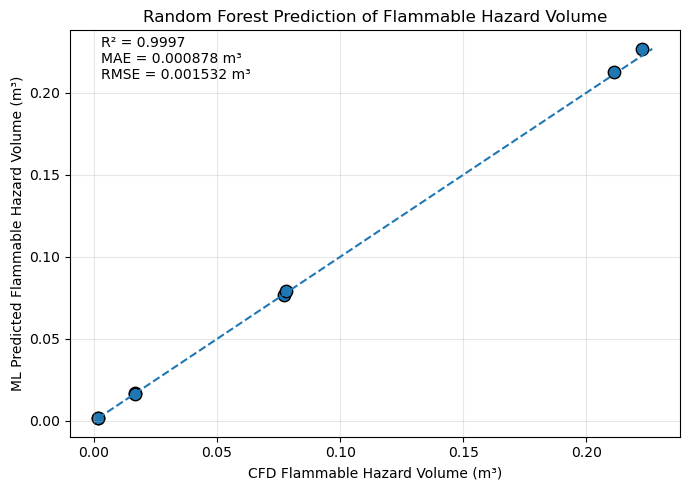

In [38]:
plt.figure(figsize=(7, 5))

plt.scatter(
    actual_volume,
    predicted_volume,
    s=80,
    edgecolor='black'
)

minimum = min(
    actual_volume.min(),
    predicted_volume.min()
)

maximum = max(
    actual_volume.max(),
    predicted_volume.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    '--'
)

plt.xlabel('CFD Flammable Hazard Volume (m³)')
plt.ylabel('ML Predicted Flammable Hazard Volume (m³)')

plt.title(
    'Random Forest Prediction of Flammable Hazard Volume'
)

plt.text(
    0.05,
    0.88,
    f'R² = {blind_volume_r2:.4f}\n'
    f'MAE = {blind_volume_mae:.6f} m³\n'
    f'RMSE = {blind_volume_rmse:.6f} m³',
    transform=plt.gca().transAxes
)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    'Model_2_Flammable_Volume_Prediction.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [39]:
volume_importance = pd.DataFrame({
    'Feature': features,
    'Importance': rf_volume_final.feature_importances_
})

volume_importance = volume_importance.sort_values(
    by='Importance',
    ascending=False
)

volume_importance

,Feature,Importance
0,Leak_Diameter_mm,0.998090
2,Wind_Sin,0.001549
1,Wind_Speed_m_s,0.000300
3,Wind_Cos,0.000062


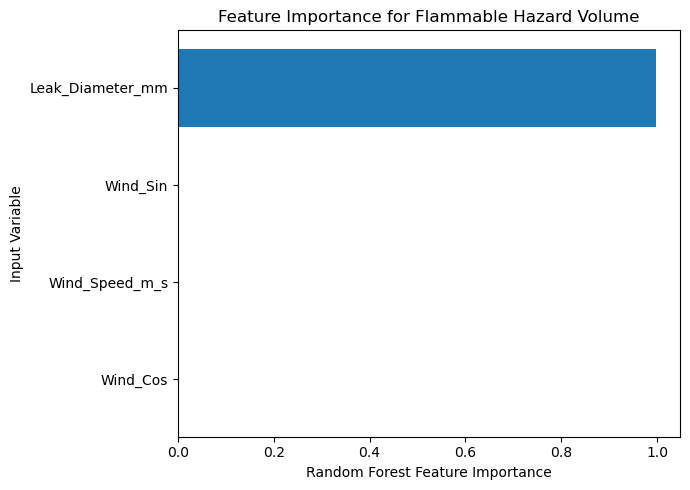

In [40]:
plt.figure(figsize=(7,5))

plt.barh(
    volume_importance['Feature'],
    volume_importance['Importance']
)

plt.xlabel('Random Forest Feature Importance')
plt.ylabel('Input Variable')
plt.title('Feature Importance for Flammable Hazard Volume')

plt.gca().invert_yaxis()

plt.tight_layout()

plt.savefig(
    'Model_2_Feature_Importance.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [41]:
X_volume_equation = development_data[[
    'Leak_Diameter_mm',
    'Wind_Speed_m_s',
    'Wind_Sin',
    'Wind_Cos'
]].copy()

X_volume_equation['Diameter_Squared'] = (
    X_volume_equation['Leak_Diameter_mm'] ** 2
)

X_volume_equation = X_volume_equation[[
    'Leak_Diameter_mm',
    'Diameter_Squared',
    'Wind_Speed_m_s',
    'Wind_Sin',
    'Wind_Cos'
]]

volume_equation_model = LinearRegression()

volume_equation_model.fit(
    X_volume_equation,
    y_volume
)

print("MODEL 2 EMPIRICAL EQUATION")
print("--------------------------")
print("Intercept =", volume_equation_model.intercept_)

for name, coefficient in zip(
    X_volume_equation.columns,
    volume_equation_model.coef_
):
    print(name, "=", coefficient)

print(
    "Development R² =",
    volume_equation_model.score(
        X_volume_equation,
        y_volume
    )
)

MODEL 2 EMPIRICAL EQUATION
--------------------------
Intercept = 0.06172272822558773
Leak_Diameter_mm = -0.018312759225883397
Diameter_Squared = 0.0013167486671453686
Wind_Speed_m_s = 0.00016809230851964202
Wind_Sin = 0.0018882587712136737
Wind_Cos = -0.00027064349651795337
Development R² = 0.9954499554949583


In [42]:
X_volume_equation_blind = blind_test_data[[
    'Leak_Diameter_mm',
    'Wind_Speed_m_s',
    'Wind_Sin',
    'Wind_Cos'
]].copy()

X_volume_equation_blind['Diameter_Squared'] = (
    X_volume_equation_blind['Leak_Diameter_mm'] ** 2
)

X_volume_equation_blind = X_volume_equation_blind[[
    'Leak_Diameter_mm',
    'Diameter_Squared',
    'Wind_Speed_m_s',
    'Wind_Sin',
    'Wind_Cos'
]]

volume_equation_predictions = (
    volume_equation_model.predict(
        X_volume_equation_blind
    )
)

volume_equation_results = pd.DataFrame({
    'Case_ID': blind_test_data['Case_ID'].values,

    'Actual_CFD_m3': blind_test_data[
        'Flammable_Hazard_Volume_m3'
    ].values,

    'Equation_Prediction_m3':
        volume_equation_predictions
})

volume_equation_results['Absolute_Error_m3'] = abs(
    volume_equation_results['Equation_Prediction_m3']
    - volume_equation_results['Actual_CFD_m3']
)

volume_equation_results['Percentage_Error'] = (
    volume_equation_results['Absolute_Error_m3']
    / volume_equation_results['Actual_CFD_m3']
) * 100

volume_equation_results

,Case_ID,Actual_CFD_m3,Equation_Prediction_m3,Absolute_Error_m3,Percentage_Error
0,1,0.001625,0.002975,0.001350,83.080675
1,12,0.222718,0.222569,0.000149,0.067019
2,18,0.016649,0.012326,0.004322,25.961620
3,31,0.077091,0.086197,0.009106,11.811789
4,35,0.077835,0.083739,0.005904,7.584667
5,46,0.016479,0.011549,0.004930,29.916926
6,56,0.211370,0.220615,0.009245,4.373817
7,57,0.001732,0.001862,0.000130,7.488770


In [43]:
volume_eq_actual = volume_equation_results['Actual_CFD_m3']
volume_eq_predicted = volume_equation_results['Equation_Prediction_m3']

volume_eq_mae = mean_absolute_error(
    volume_eq_actual,
    volume_eq_predicted
)

volume_eq_rmse = np.sqrt(
    mean_squared_error(
        volume_eq_actual,
        volume_eq_predicted
    )
)

volume_eq_r2 = r2_score(
    volume_eq_actual,
    volume_eq_predicted
)

volume_eq_mape = (
    volume_equation_results['Percentage_Error'].mean()
)

print("MODEL 2 EMPIRICAL EQUATION: BLIND TEST")
print("--------------------------------------")
print(f"MAE  = {volume_eq_mae:.6f} m³")
print(f"RMSE = {volume_eq_rmse:.6f} m³")
print(f"R²   = {volume_eq_r2:.4f}")
print(f"MAPE = {volume_eq_mape:.2f} %")

MODEL 2 EMPIRICAL EQUATION: BLIND TEST
--------------------------------------
MAE  = 0.004392 m³
RMSE = 0.005569 m³
R²   = 0.9957
MAPE = 21.29 %
